# Retailrocket EDA

Цель проекта - понять, как посетители взаимодействуют с товарами и на каких этапах теряется интерес к покупке.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", None)

In [2]:
data_dir = Path("../data")
events = pd.read_csv(data_dir / "events.csv")
events.head()

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [3]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB


## Базовая воронка

Сначала сравним просмотры, добавления в корзину и покупки среди уникальных посетителей. Это даст базовый ориентир, с которым потом можно будет сравнивать отдельные часы, категории и группы пользователей.

In [4]:
print("Уникальных посетителей всего:", events["visitorid"].nunique())

funnel = (
    events
    .groupby("event")
    .agg(
        events=("event", "size"),
        visitors=("visitorid", "nunique")
    )
    .reindex(["view", "addtocart", "transaction"])
)

funnel["share_of_viewers"] = (
    funnel["visitors"] / funnel.loc["view", "visitors"]
)

funnel

Уникальных посетителей всего: 1407580


,events,visitors,share_of_viewers
event,,,
view,2664312,1404179,1.000000
addtocart,69332,37722,0.026864
transaction,22457,11719,0.008346


## Показатели по часам

Проверим, меняется ли доля покупок в зависимости от часа суток. Если разница окажется устойчивой, её можно будет использовать как направление для дальнейшего анализа поведения пользователей.

In [5]:
events["event_time"] = pd.to_datetime(events["timestamp"], unit="ms")
events["hour"] = events["event_time"].dt.hour

hourly = (
    events
    .groupby(["hour", "event"])["visitorid"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=["view", "addtocart", "transaction"], fill_value=0)
)

hourly["purchase_rate"] = hourly["transaction"] / hourly["view"]
hourly

event,view,addtocart,transaction,purchase_rate
hour,,,,
0,89168,2283,682,0.007648
1,88570,2203,629,0.007102
2,92317,2181,660,0.007149
3,96192,2241,613,0.006373
4,93129,2216,585,0.006282
5,75495,1869,542,0.007179
6,49382,1232,359,0.007270
7,28347,652,189,0.006667
8,16842,346,79,0.004691


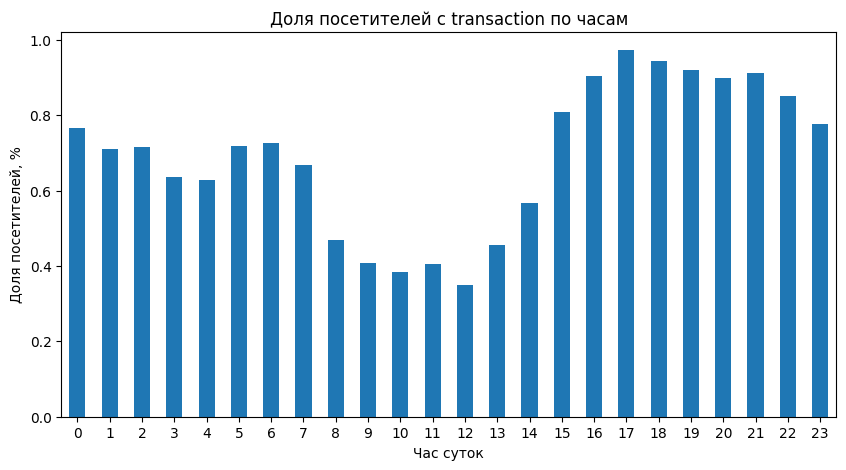

In [6]:
hourly["purchase_rate"].mul(100).plot(
    kind="bar",
    figsize=(10, 5),
    title="Доля посетителей с transaction по часам"
)

plt.xlabel("Час суток")
plt.ylabel("Доля посетителей, %")
plt.xticks(rotation=0)
plt.show()

## Свойства товаров

Чтобы сравнивать поведение по категориям, нужно связать события с характеристиками товаров. Сначала посмотрим, какие свойства доступны и какие из них имеют понятный смысл.

In [7]:
properties_part1 = pd.read_csv(data_dir / "item_properties_part1.csv")
properties_part1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999999 entries, 0 to 10999998
Data columns (total 4 columns):
 #   Column     Dtype 
---  ------     ----- 
 0   timestamp  int64 
 1   itemid     int64 
 2   property   object
 3   value      object
dtypes: int64(2), object(2)
memory usage: 335.7+ MB


In [8]:
print(properties_part1["property"].value_counts().to_string())

property
888           1629817
790            970800
available      817387
categoryid     426305
6              343207
283            323681
776            311654
678            261829
364            256340
202            242984
839            226921
159            226502
917            226437
764            226242
112            226102
227            188209
698            157281
451            142388
663            131331
962            128976
400            118416
689            116244
28              93598
928             87128
1036            79306
810             77540
544             62450
348             61416
713             56559
1032            44011
19              41218
566             39614
581             36959
978             34777
981             33873
720             30199
960             29602
243             29445
38              29413
46              29310
434             29117
71              28424
797             27865
591             27420
961             27000
4